[*] Generating Bipartite Flow Network...
[✓] Plot saved successfully as network_flow_bipartite.png


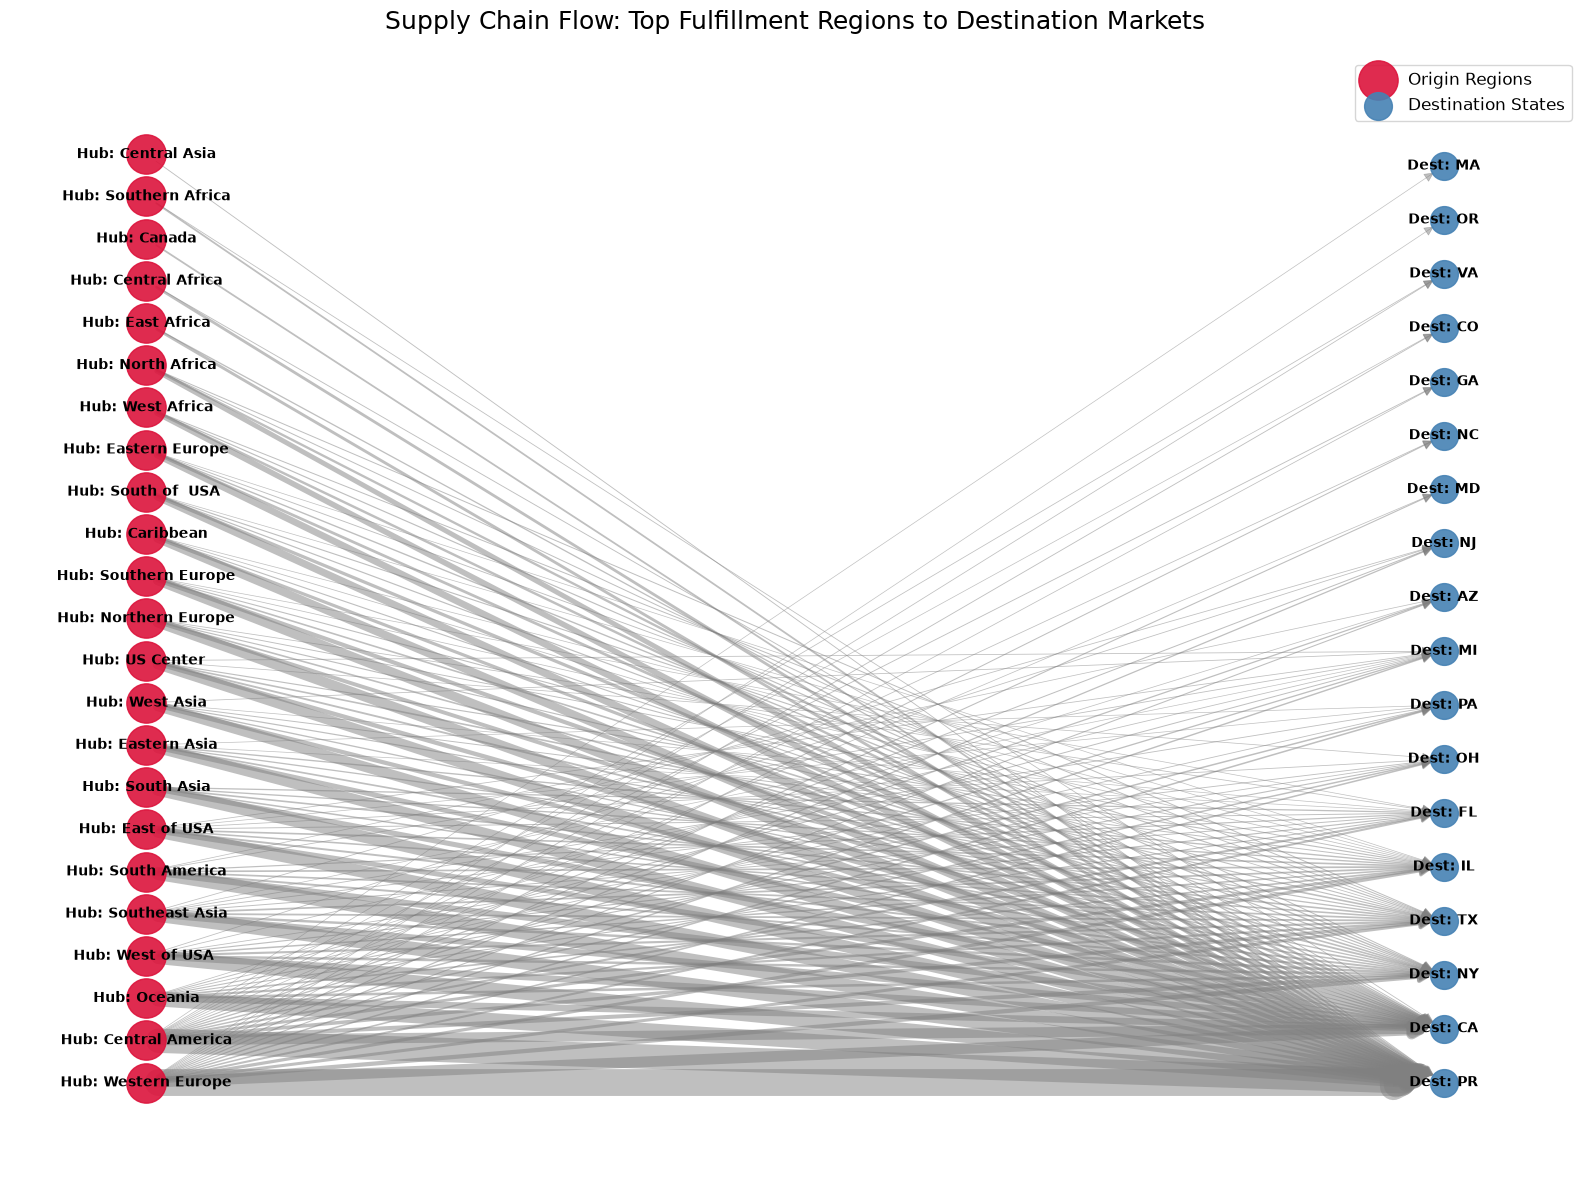

In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

print("[*] Generating Bipartite Flow Network...")
# Load the raw tabular data to get the actual region names and shipment volumes
df = pd.read_parquet("../data/processed/train.parquet")

# Aggregate shipments to find the busiest routes
flow_df = df.groupby(['Order Region', 'Customer State']).size().reset_index(name='shipments')

# Filter to the top 150 busiest routes to remove visual noise
top_flows = flow_df.sort_values('shipments', ascending=False).head(150)

# Build a directed graph
G = nx.DiGraph()
for _, row in top_flows.iterrows():
    # Add a suffix to differentiate just in case a region and state share a name
    orig = f"Hub: {row['Order Region']}"
    dest = f"Dest: {row['Customer State']}"
    G.add_edge(orig, dest, weight=row['shipments'])

origins = [n for n in G.nodes if n.startswith("Hub:")]
dests = [n for n in G.nodes if n.startswith("Dest:")]

plt.figure(figsize=(16, 12))

# Create a clear Bipartite Layout (Origins Left, Destinations Right)
pos = {}
for i, node in enumerate(origins):
    pos[node] = (-1, i * (100 / max(len(origins), 1)))
for i, node in enumerate(dests):
    pos[node] = (1, i * (100 / max(len(dests), 1)))

# Draw Origins (Red, Larger) and Destinations (Blue, Smaller)
nx.draw_networkx_nodes(G, pos, nodelist=origins, node_color='crimson', node_size=800, alpha=0.9, label="Origin Regions")
nx.draw_networkx_nodes(G, pos, nodelist=dests, node_color='steelblue', node_size=400, alpha=0.9, label="Destination States")

# Draw edges, scaling thickness by the volume of shipments
weights = [G[u][v]['weight'] / 300 for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=weights, edge_color='gray', alpha=0.5, arrows=True, arrowsize=15)

# Add text labels so reviewers know what these nodes actually represent
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold', font_color='black')

plt.title("Supply Chain Flow: Top Fulfillment Regions to Destination Markets", fontsize=18, pad=20)
plt.legend(scatterpoints=1, loc='upper right', fontsize=12)
plt.axis('off')
plt.tight_layout()

# Save the high-res visualization
plt.savefig("../network_flow_bipartite.png", dpi=300, bbox_inches='tight')
print("[✓] Plot saved successfully as network_flow_bipartite.png")
plt.show()

[*] Generating Clean Bipartite Flow Network...
[✓] Plot saved successfully as network_flow_bipartite.png


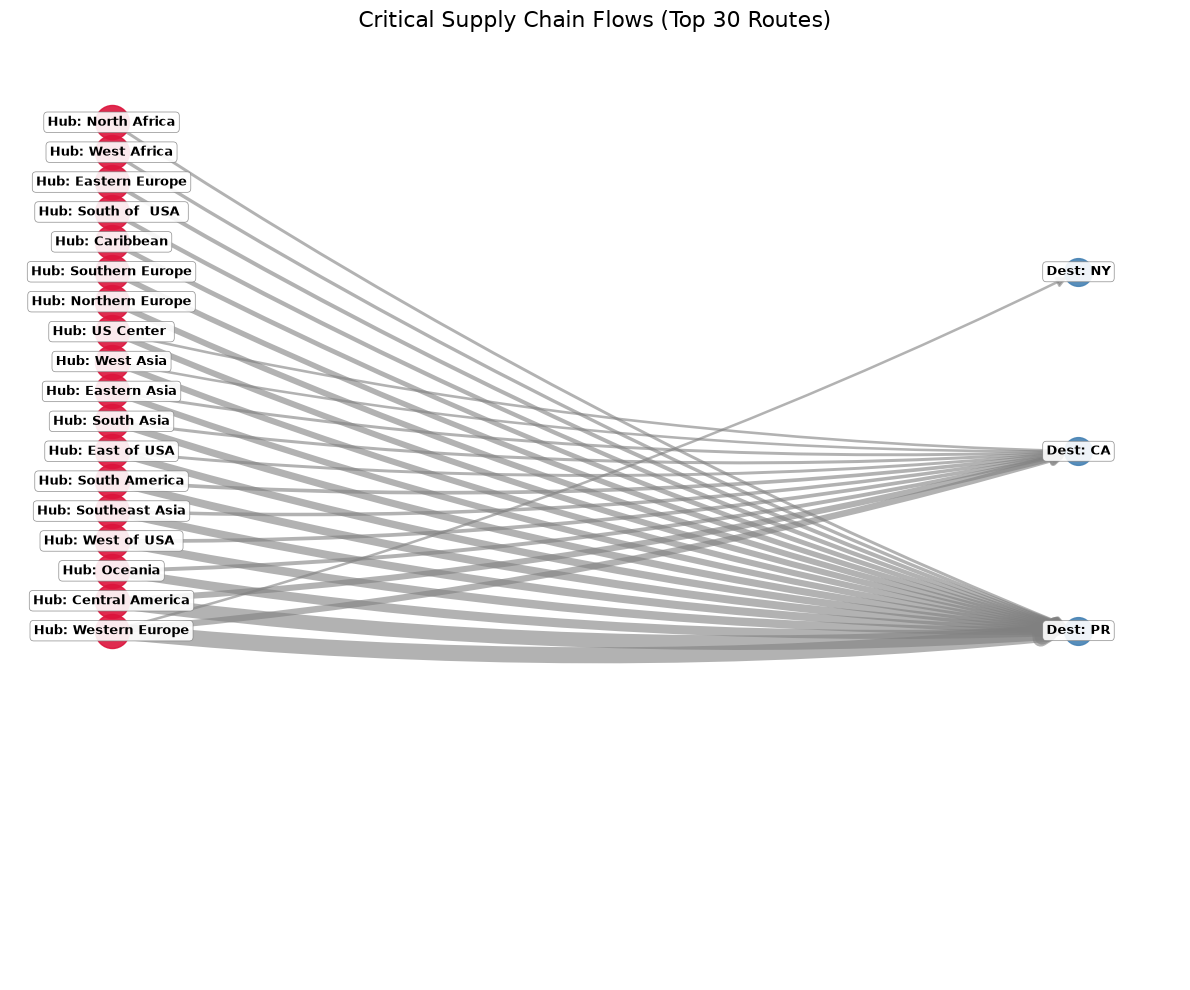

In [3]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

print("[*] Generating Clean Bipartite Flow Network...")
df = pd.read_parquet("../data/processed/train.parquet")

# Aggregate shipments to find the busiest routes
flow_df = df.groupby(['Order Region', 'Customer State']).size().reset_index(name='shipments')

# Filter down to the Top 30 critical flows so the graph is actually readable
top_flows = flow_df.sort_values('shipments', ascending=False).head(30)

G = nx.DiGraph()
for _, row in top_flows.iterrows():
    orig = f"Hub: {row['Order Region']}"
    dest = f"Dest: {row['Customer State']}"
    G.add_edge(orig, dest, weight=row['shipments'])

origins = [n for n in G.nodes if n.startswith("Hub:")]
dests = [n for n in G.nodes if n.startswith("Dest:")]

plt.figure(figsize=(12, 10))

# Simple, even spacing for the layout
pos = {}
for i, node in enumerate(origins):
    pos[node] = (-1, i)
for i, node in enumerate(dests):
    # Scale destination Y-coordinates to match the height of origins
    pos[node] = (1, i * (len(origins) / max(len(dests), 1)))

# Draw Nodes
nx.draw_networkx_nodes(G, pos, nodelist=origins, node_color='crimson', node_size=600, alpha=0.9)
nx.draw_networkx_nodes(G, pos, nodelist=dests, node_color='steelblue', node_size=400, alpha=0.9)

# Draw Edges with width scaled down
weights = [G[u][v]['weight'] / 500 for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=weights, edge_color='gray', alpha=0.6, arrows=True, arrowsize=15, connectionstyle="arc3,rad=0.05")

# Draw Labels with a bounding box so they don't blend into the lines
bbox_props = dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=0.5, alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold', bbox=bbox_props)

plt.title("Critical Supply Chain Flows (Top 30 Routes)", fontsize=16, pad=20)
plt.axis('off')
plt.tight_layout()

plt.savefig("../network_flow_bipartite.png", dpi=300, bbox_inches='tight')
print("[✓] Plot saved successfully as network_flow_bipartite.png")
plt.show()

In [1]:
from stockpyl.instances import load_instance

# Loads a real multi-echelon industrial supply chain instance from Willems (2008)
network = load_instance("example_6_1")
print(f"Nodes: {len(network.nodes)} | Edges: {len(network.edges)}")
for node in network.nodes[:5]:
    print(f"Node {node.index}: Processing Time={node.processing_time}, Holding Cost={node.local_holding_cost}")

Nodes: 3 | Edges: 2
Node 3: Processing Time=None, Holding Cost=2
Node 2: Processing Time=None, Holding Cost=4
Node 1: Processing Time=None, Holding Cost=7


In [2]:
import json
from pathlib import Path
import stockpyl
from stockpyl.instances import load_instance

# 1. Inspect all bundled instance names in your stockpyl install
inst_dir = Path(stockpyl.__file__).parent / "datasets"
for jf in inst_dir.glob("*.json"):
    with open(jf, "r") as f:
        data = json.load(f)
    names = list(data.keys()) if isinstance(data, dict) else [d.get("name") for d in data]
    print(f"{jf.name}: {len(names)} instances -> sample: {names[:10]}")

stockpyl_instances.json: 3 instances -> sample: ['_id', 'instances', 'last_updated']


In [3]:
import json
from pathlib import Path
import stockpyl

jf = Path(stockpyl.__file__).parent / "datasets" / "stockpyl_instances.json"
with open(jf, "r") as f:
    raw = json.load(f)

instances = raw["instances"]
summary = []
for inst in instances:
    name = inst.get("name")
    desc = inst.get("description", "")
    # Count nodes inside the serialized network dict
    net_data = inst.get("data", {})
    n_nodes = len(net_data.get("nodes", []))
    summary.append((n_nodes, name, desc))

for n_nodes, name, desc in sorted(summary, reverse=True)[:20]:
    print(f"{n_nodes:>3} nodes | {name:<25} | {desc[:65]}")

  0 nodes | spp_jrp                   | Numerical JRP example on p. 428 of Silver, Pyke, and Peterson (19
  0 nodes | silver_jrp                | Numerical JRP example in Silver (1976)
  0 nodes | shang_song_9              | Serial SSM system in Shang and Song (2003), Table 1, row 9
  0 nodes | shang_song_25             | Serial SSM system in Shang and Song (2003), Table 1, row 25
  0 nodes | shang_song_17             | Serial SSM system in Shang and Song (2003), Table 1, row 17
  0 nodes | shang_song_1              | Serial SSM system in Shang and Song (2003), Table 1, row 1
  0 nodes | scmo_ww_hw_c              | SCMO (Wagner-Whitin with nonstationary purchase cost)
  0 nodes | scmo_jrp_hw_3             | SCMO (JRP problem 3)
  0 nodes | scmo_jrp_hw_2             | SCMO (JRP problem 2)
  0 nodes | scmo_jrp_hw_1             | SCMO (JRP problem 1)
  0 nodes | scmo_jrp_ex               | SCMO (JRP example)
  0 nodes | rosling_figure_1          | Assembly system from Figure 1 in Rosling 

In [5]:
import os
import pandas as pd
from stockpyl.instances import load_instance

for name in ["rosling_figure_1", "rong_atan_snyder_figure_1c", "problem_6_9"]:
    net = load_instance(name)
    print(f"\n=== {name} | Nodes: {len(net.nodes)} | Edges: {len(net.edges)} ===")
    for n in net.nodes:
        lt = getattr(n, "lead_time", None)
        pt = getattr(n, "processing_time", None)
        hc = getattr(n, "local_holding_cost", None)
        succ = [s.index for s in n.successors()]
        print(f"  Node {n.index:>2} -> {succ} | LT={lt} | PT={pt} | HoldingCost={hc}")

# Inspect your existing cleaned DataCo files and columns
print("\n=== Files in data/ ===")
for root, _, files in os.walk("data"):
    for file in files:
        path = os.path.join(root, file)
        print(path)
        if file.endswith(".csv"):
            cols = pd.read_csv(path, nrows=1).columns.tolist()
            print(f"  Columns ({len(cols)}): {cols}")


=== rosling_figure_1 | Nodes: 7 | Edges: 6 ===
  Node  1 -> [] | LT=1 | PT=None | HoldingCost=None
  Node  2 -> [1] | LT=1 | PT=None | HoldingCost=None
  Node  3 -> [1] | LT=3 | PT=None | HoldingCost=None
  Node  4 -> [3] | LT=2 | PT=None | HoldingCost=None
  Node  5 -> [2] | LT=4 | PT=None | HoldingCost=None
  Node  6 -> [4] | LT=1 | PT=None | HoldingCost=None
  Node  7 -> [4] | LT=2 | PT=None | HoldingCost=None

=== rong_atan_snyder_figure_1c | Nodes: 6 | Edges: 5 ===
  Node  0 -> [1, 2] | LT=None | PT=None | HoldingCost=None
  Node  1 -> [] | LT=None | PT=None | HoldingCost=None
  Node  2 -> [3, 4, 5] | LT=None | PT=None | HoldingCost=None
  Node  3 -> [] | LT=None | PT=None | HoldingCost=None
  Node  4 -> [] | LT=None | PT=None | HoldingCost=None
  Node  5 -> [] | LT=None | PT=None | HoldingCost=None

=== problem_6_9 | Nodes: 6 | Edges: 5 ===
  Node  1 -> [] | LT=None | PT=7 | HoldingCost=0.12054794520547946
  Node  2 -> [] | LT=None | PT=7 | HoldingCost=0.07671232876712329
  Node